# Model for F4 weapon types
Very simple model for forecasting Weapon type class of F4 Strike missions.


Models included: 
- logistic regression
- random forest
- support vector machine

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import time
import numpy as np
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay


Dataset is limited to F-4 Phantoms which carry out Strike missions. Strike 
missions are preplanned missions.
We are trying to forecast what weapon type is utilized.  

Y-variables are:
- year
- target category


In [19]:
df = pd.read_parquet("THOR_Analysis.parquet")
df = df.loc[df["AIRCRAFT_ROOT"] == "F4"].copy()
df = df.loc[df["MFUNC_DESC"] == "STRIKE"].copy()

## Logistic regression model

In [20]:


df = pd.read_parquet("THOR_Analysis.parquet")
df = df.loc[
    (df["AIRCRAFT_ROOT"] == "F4") & (df["MFUNC_DESC"] == "STRIKE")
].copy()

data = df.loc[
    df["WEAPONTYPECLASS"].notna()
    & (df["WEAPONTYPECLASS"] != "UNDEFINED")
].copy()

data["year"] = pd.to_datetime(data["missiondate"], errors="coerce").dt.year

X = data[["year", "targetcategory"]]
y = data["WEAPONTYPECLASS"]

print("Class counts:")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocess = ColumnTransformer([
    ("year", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), ["year"]),
    ("target", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore")),
    ]), ["targetcategory"]),
])

model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(max_iter=1000)),
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(classification_report(y_test, predictions, zero_division=0))

Class counts:
WEAPONTYPECLASS
BOMB       172048
ROCKET      18074
MISSILE     10704
GUN           478
SUPPORT       372
Name: count, dtype: int64
              precision    recall  f1-score   support

        BOMB       0.85      1.00      0.92     34410
         GUN       0.00      0.00      0.00        96
     MISSILE       0.00      0.00      0.00      2141
      ROCKET       0.00      0.00      0.00      3615
     SUPPORT       0.00      0.00      0.00        74

    accuracy                           0.85     40336
   macro avg       0.17      0.20      0.18     40336
weighted avg       0.73      0.85      0.79     40336



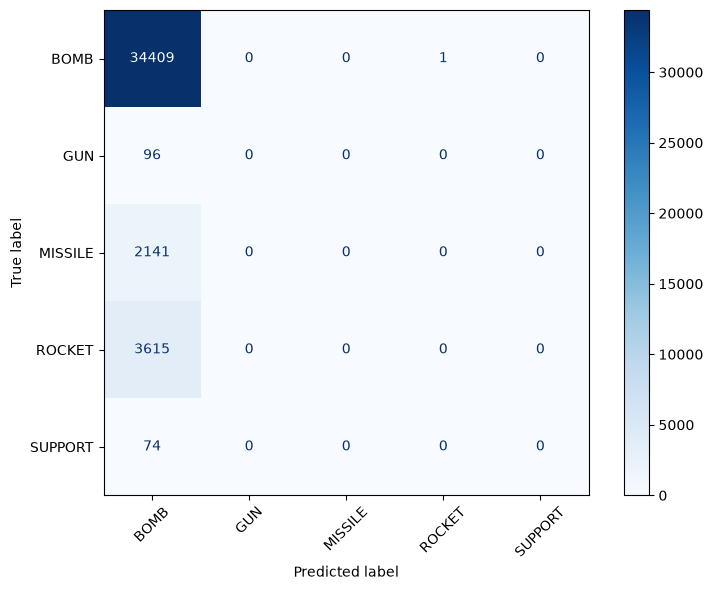

In [21]:


fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, cmap="Blues", xticks_rotation=45, ax=ax
)
plt.tight_layout()
plt.show()

## Random forest model

In [22]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocess", clone(preprocess)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced",
    )),
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

print(classification_report(y_test, rf_predictions, zero_division=0))

              precision    recall  f1-score   support

        BOMB       0.91      0.22      0.35     34410
         GUN       0.03      0.83      0.06        96
     MISSILE       0.08      0.43      0.13      2141
      ROCKET       0.20      0.60      0.30      3615
     SUPPORT       0.00      0.39      0.01        74

    accuracy                           0.27     40336
   macro avg       0.24      0.49      0.17     40336
weighted avg       0.80      0.27      0.34     40336



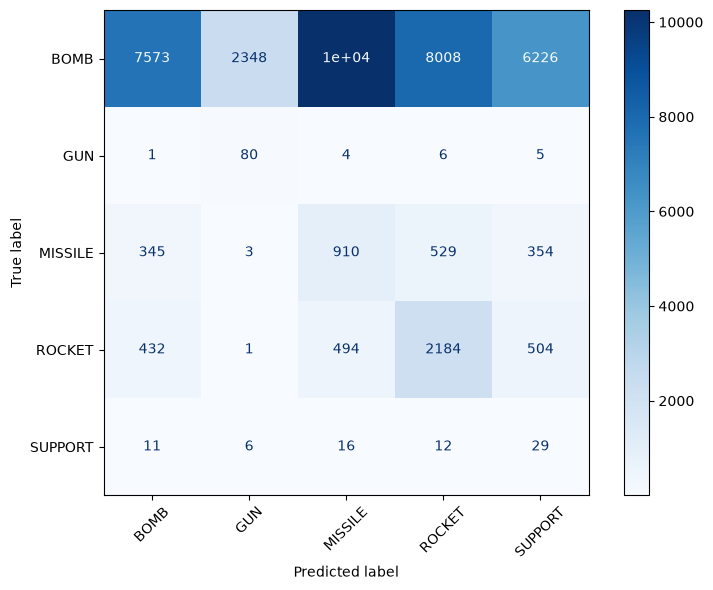

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions, cmap="Blues", xticks_rotation=45, ax=ax
)
plt.tight_layout()
plt.show()

## Support vector machine model

In [24]:
from sklearn.base import clone
from sklearn.svm import LinearSVC

svm_model = Pipeline([
    ("preprocess", clone(preprocess)),
    ("classifier", LinearSVC(
        class_weight="balanced",
        dual="auto",
        max_iter=5000,
        random_state=42,
    )),
])

svm_model.fit(X_train, y_train)
svm_predictions = svm_model.predict(X_test)

print(classification_report(y_test, svm_predictions, zero_division=0))

              precision    recall  f1-score   support

        BOMB       0.86      0.93      0.90     34410
         GUN       0.00      0.00      0.00        96
     MISSILE       0.00      0.00      0.00      2141
      ROCKET       0.24      0.20      0.21      3615
     SUPPORT       0.00      0.00      0.00        74

    accuracy                           0.81     40336
   macro avg       0.22      0.23      0.22     40336
weighted avg       0.76      0.81      0.78     40336



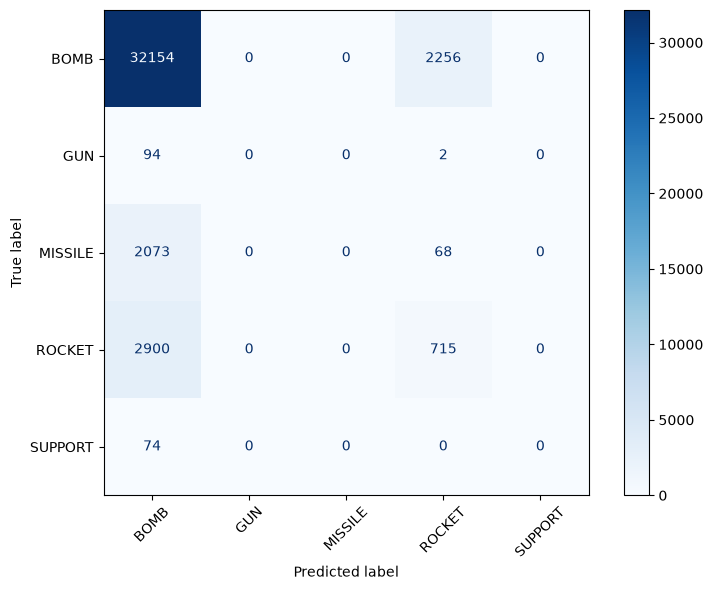

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_predictions, cmap="Blues", xticks_rotation=45, ax=ax
)
plt.tight_layout()
plt.show()

## Combined metrics

In [26]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

rows = []
for name, fitted_model in [
    ("Logistic regression", model),
    ("Random forest", rf_model),
    ("Support vector machine", svm_model),
]:
    predictions = fitted_model.predict(X_test)
    scores = (
        fitted_model.predict_proba(X_test)
        if hasattr(fitted_model, "predict_proba")
        else fitted_model.decision_function(X_test)
    )
    roc_auc = np.mean([
        roc_auc_score(y_test == class_label, scores[:, class_index])
        for class_index, class_label in enumerate(fitted_model.classes_)
    ])

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "ROC AUC (macro OvR)": roc_auc,
    })

comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(3))

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC AUC (macro OvR)
Model,,,,,
Logistic regression,0.853,0.171,0.200,0.184,0.720
Random forest,0.267,0.245,0.495,0.172,0.737
Support vector machine,0.815,0.219,0.226,0.222,0.714
